# Question 1

In [1]:
%matplotlib widget

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
image_path = Path("../a2images/the_berry_farms_sunflower_field.jpeg")
image_bgr = cv2.imread(str(image_path), cv2.IMREAD_REDUCED_COLOR_4)

if image_bgr is None:
    raise FileNotFoundError(f"Could not read image: {image_path.resolve()}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
print(f"Image dimensions: {gray.shape[1]} × {gray.shape[0]} pixels")

Image dimensions: 360 × 360 pixels


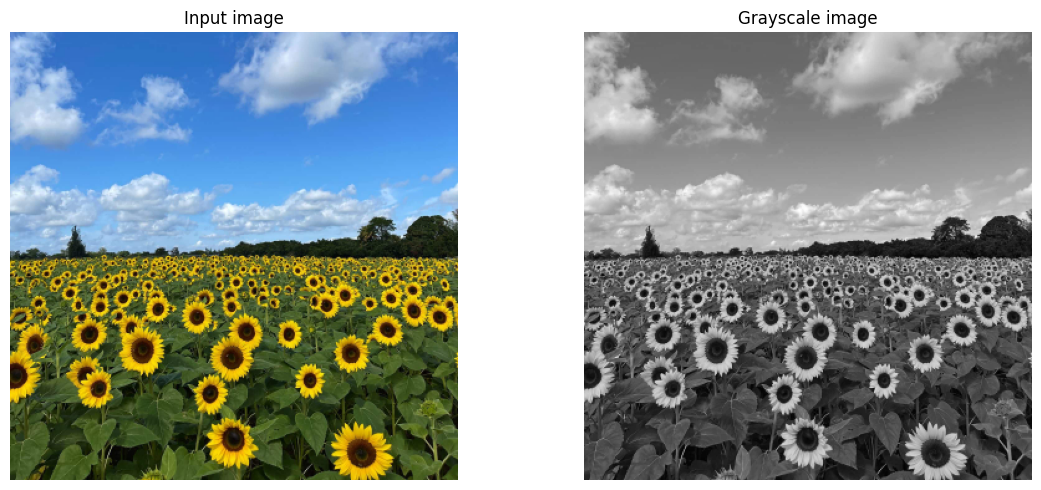

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image_rgb)
axes[0].set_title("Input image")
axes[0].axis("off")
axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale image")
axes[1].axis("off")
plt.tight_layout()

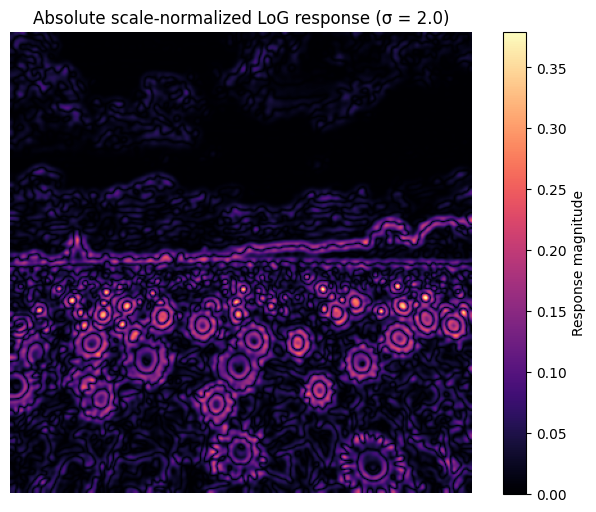

In [4]:
sigma = 2.0
gray_float = gray.astype(np.float32) / 255.0
smoothed = cv2.GaussianBlur(
    gray_float,
    ksize=(0, 0),
    sigmaX=sigma,
    sigmaY=sigma,
)
laplacian = cv2.Laplacian(smoothed, cv2.CV_32F)
log_response = sigma**2 * laplacian

plt.figure(figsize=(8, 6))
plt.imshow(np.abs(log_response), cmap="magma")
plt.title(f"Absolute scale-normalized LoG response (σ = {sigma})")
plt.axis("off")
plt.colorbar(label="Response magnitude")
plt.show()

# Question 2

In [ ]:
rng = np.random.default_rng(0)
N = 100
half_n = N // 2

# Noisy circle points (ground truth is useful for checking the plot later).
circle_radius_gt = 10.0
circle_center_gt = np.array([2.0, 3.0])
t = rng.uniform(0, 2 * np.pi, half_n)
radial_noise = (circle_radius_gt / 16) * rng.standard_normal(half_n)
X_circle = np.column_stack((
    circle_center_gt[0] + (circle_radius_gt + radial_noise) * np.cos(t),
    circle_center_gt[1] + (circle_radius_gt + radial_noise) * np.sin(t),
))

# Noisy line points.
line_slope_gt, line_intercept_gt = -1.0, 2.0
x_line = np.linspace(-12, 12, half_n)
y_line = line_slope_gt * x_line + line_intercept_gt + rng.standard_normal(half_n)
X_line = np.column_stack((x_line, y_line))
X = np.vstack((X_circle, X_line))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[:, 0], X[:, 1], s=18, label="All noisy points")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
ax.grid(True)
plt.show()

In [ ]:
def line_from_two_points(p1, p2):
    """Return (a, b, d) for a unit-normal line a*x + b*y = d."""
    direction = p2 - p1
    length = np.linalg.norm(direction)
    if length < 1e-12:
        return None
    normal = np.array([-direction[1], direction[0]]) / length
    return normal[0], normal[1], float(normal @ p1)


def ransac_line(points, threshold=1.5, min_inliers=35, iterations=2000, seed=0):
    """Find a line with two-point RANSAC; return model, inlier mask, sample."""
    random = np.random.default_rng(seed)
    best_model, best_mask, best_sample = None, None, None
    for _ in range(iterations):
        sample = random.choice(len(points), size=2, replace=False)
        model = line_from_two_points(points[sample[0]], points[sample[1]])
        if model is None:
            continue
        a, b, d = model
        errors = np.abs(points @ np.array([a, b]) - d)
        mask = errors < threshold
        if best_mask is None or mask.sum() > best_mask.sum():
            best_model, best_mask, best_sample = model, mask, sample

    if best_mask is None or best_mask.sum() < min_inliers:
        raise RuntimeError("RANSAC did not find a line with enough consensus points.")

    # Refit using all consensus points with total least squares, preserving ||[a,b]||=1.
    inlier_points = points[best_mask]
    centroid = inlier_points.mean(axis=0)
    _, _, vh = np.linalg.svd(inlier_points - centroid, full_matrices=False)
    normal = vh[-1]
    d = float(normal @ centroid)
    return (float(normal[0]), float(normal[1]), d), best_mask, best_sample

line_model, line_inliers, line_sample = ransac_line(X, threshold=1.5, min_inliers=35)
a, b, d = line_model
print(f"Line: {a:.4f} x + {b:.4f} y = {d:.4f}")
print(f"Consensus points: {line_inliers.sum()} / {len(X)}")
print(f"Two-point sample indices: {line_sample}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[~line_inliers, 0], X[~line_inliers, 1], s=18, color="0.75", label="Non-inliers")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=22, label="Line inliers")
sample_points = X[line_sample]
ax.scatter(sample_points[:, 0], sample_points[:, 1], s=75, marker="x", label="Best two-point sample")
x_limits = np.array(ax.get_xlim())
if abs(b) > 1e-8:
    ax.plot(x_limits, (d - a * x_limits) / b, "r-", label="RANSAC line")
else:
    x_value = d / a
    ax.axvline(x_value, color="r", label="RANSAC line")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
ax.grid(True)
plt.show()

# Question 3

In [ ]:
architecture_path = Path("../a2images/wadham.jpg")
flag_path = Path("../a2images/flag.png")
architecture_bgr = cv2.imread(str(architecture_path), cv2.IMREAD_COLOR)
flag_bgra = cv2.imread(str(flag_path), cv2.IMREAD_UNCHANGED)
if architecture_bgr is None or flag_bgra is None:
    raise FileNotFoundError("Could not load wadham.jpg and flag.png from ../a2images")
architecture_rgb = cv2.cvtColor(architecture_bgr, cv2.COLOR_BGR2RGB)
flag_rgb = cv2.cvtColor(flag_bgra[:, :, :3], cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(architecture_rgb)
axes[0].set_title("Architecture: select four destination points")
axes[0].axis("off")
axes[1].imshow(flag_rgb)
axes[1].set_title("Source flag image")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Click four planar-surface corners in the left image, in clockwise order.
# Click the four corners in the displayed image, then press Enter.
selected = plt.ginput(4, timeout=0)
if len(selected) != 4:
    raise ValueError("Select exactly four destination points.")
destination_corners = np.asarray(selected, dtype=np.float32)
print("Destination corners (clockwise):\n", destination_corners)

# Question 4

In [ ]:
pcb_dir = Path("../a2images/pcbs")
template_path = pcb_dir / "AECC1.jpg"
pcb_path = pcb_dir / "AECC2.jpg"  # Change this to inspect another PCB image.
template_bgr = cv2.imread(str(template_path), cv2.IMREAD_COLOR)
pcb_bgr = cv2.imread(str(pcb_path), cv2.IMREAD_COLOR)
if template_bgr is None or pcb_bgr is None:
    raise FileNotFoundError(f"Could not load {template_path} or {pcb_path}")

template_gray = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2GRAY)
pcb_gray = cv2.cvtColor(pcb_bgr, cv2.COLOR_BGR2GRAY)
sift = cv2.SIFT_create()
template_keypoints, template_descriptors = sift.detectAndCompute(template_gray, None)
pcb_keypoints, pcb_descriptors = sift.detectAndCompute(pcb_gray, None)
print(f"Template SIFT features: {len(template_keypoints)}")
print(f"PCB SIFT features: {len(pcb_keypoints)}")

shown = cv2.drawKeypoints(template_bgr, template_keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
shown_pcb = cv2.drawKeypoints(pcb_bgr, pcb_keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(shown, cv2.COLOR_BGR2RGB))
axes[0].set_title("Template SIFT keypoints")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(shown_pcb, cv2.COLOR_BGR2RGB))
axes[1].set_title("PCB image SIFT keypoints")
axes[1].axis("off")
plt.tight_layout()
plt.show()